# 06. <span style="color:#7CDBA0">Dataset</span> и <span style="color:#6CB6FF">DataLoader</span> — ч.3 (практика)

Видео: [6. Подготовка данных ч.3. <span style="color:#7CDBA0">Dataset</span> и <span style="color:#6CB6FF">DataLoader</span>](https://www.youtube.com/watch?v=GKRZAflTnQI&list=PLBP4Q3FNSLK2rtGPBsK-aMAetYj-8yg_1&index=7)

## Зачем

Видео 5 — свой <span style="color:#7CDBA0">Dataset</span> «с нуля». Здесь два продолжения автора:

1. **<span style="color:#E6C07B">ImageFolder</span>** — та же раскладка «папка = класс», но одной строкой (то, что мы руками писали как `FruitsDataset`).
2. **Регрессия** — картинки + json с числами (не классами). Как у автора: светлый **квадрат** на картинке → предсказать центр `(cx, cy)` формы `(2,)`.

**Как смотреть.** Видео короткое (~8 мин) — можно целиком. Удобнее кусками по таблице → пауза → блок.

| блок | о чём | где в видео |
|:---|:---|:---|
| 1 | <span style="color:#E6C07B">ImageFolder</span> на фруктах | 0:00–2:38 |
| 2 | свой <span style="color:#7CDBA0">SquaresDataset</span> (регрессия) | 2:38–7:47 |

**Как решать.** Замени `...` на код → запусти проверку. Решения — в `06_dataset_dataloader_3_решения.ipynb`, только после своей попытки.


In [189]:
import json
import os
import shutil

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Grayscale, ToTensor

torch.manual_seed(0)

# ImageFolder по умолчанию открывает картинку как RGB → ToTensor даёт (3, H, W).
# Наши фрукты серые — как в 05 оставляем 1 канал.
GRAY_TENSOR = Compose([Grayscale(num_output_channels=1), ToTensor()])


def need(cond, msg):
    assert cond, msg


def need_tensor(x, name):
    assert isinstance(x, torch.Tensor), f"{name} — пока не тензор (замени ... на код)"


## 0. Данные

Ячейка ниже создаёт `_data/` рядом с ноутбуком:

```text
_data/
├── fruits/
│   ├── train/  apple|pear|plum  (+ мусорные txt — ImageFolder их игнорит)
│   └── test/   apple|pear|plum
└── squares/
    ├── img_000.png … img_199.png   # 64×64, серый фон + светлый квадрат 15×15
    └── labels.json                 # {"img_000.png": [cx, cy], ...}
```

Фрукты — как в `05` (проверка `ImageFolder`). Квадраты — мини-версия регрессии автора (у него 100 000; нам хватит 200).

У автора в json порядок `[y, x]`. Здесь удобнее `[cx, cy]` (сначала x, потом y) — на проверках и в `scatter` так привычнее.


In [190]:
DATA_ROOT = os.path.join(".", "_data")
FRUITS_TRAIN = os.path.join(DATA_ROOT, "fruits", "train")
FRUITS_TEST = os.path.join(DATA_ROOT, "fruits", "test")
SQUARES_DIR = os.path.join(DATA_ROOT, "squares")
LABELS_PATH = os.path.join(SQUARES_DIR, "labels.json")


def _write_fruit_png(path, value):
    arr = np.full((8, 8), value, dtype=np.uint8)
    Image.fromarray(arr, mode="L").save(path)


def _make_fruits():
    layout = {
        "train": {"apple": 12, "pear": 10, "plum": 3},
        "test": {"apple": 4, "pear": 4, "plum": 4},
    }
    brightness = {"apple": 40, "pear": 120, "plum": 200}
    for split, classes in layout.items():
        for cls, n in classes.items():
            d = os.path.join(DATA_ROOT, "fruits", split, cls)
            os.makedirs(d, exist_ok=True)
            for i in range(n):
                _write_fruit_png(
                    os.path.join(d, f"{cls}_{i:03d}.png"), brightness[cls]
                )
        open(os.path.join(DATA_ROOT, "fruits", split, "README.txt"), "w", encoding="utf-8").write("skip\n")
    open(
        os.path.join(DATA_ROOT, "fruits", "train", "pear", "notes.txt"),
        "w",
        encoding="utf-8",
    ).write("not an image\n")


def _draw_square(cx, cy, side=15, size=64):
    img = Image.new("L", (size, size), color=30)
    draw = ImageDraw.Draw(img)
    half = side // 2
    box = [cx - half, cy - half, cx - half + side - 1, cy - half + side - 1]
    draw.rectangle(box, fill=220)
    return img


def _make_squares(n=200, size=64, side=15, seed=0):
    os.makedirs(SQUARES_DIR, exist_ok=True)
    rng = np.random.default_rng(seed)
    labels = {}
    half = side // 2
    for i in range(n):
        name = f"img_{i:03d}.png"
        cx = int(rng.integers(half, size - half))
        cy = int(rng.integers(half, size - half))
        _draw_square(cx, cy, side=side, size=size).save(os.path.join(SQUARES_DIR, name))
        labels[name] = [float(cx), float(cy)]
    with open(LABELS_PATH, "w", encoding="utf-8") as f:
        json.dump(labels, f, indent=2)
    return n


if not os.path.isdir(FRUITS_TRAIN):
    _make_fruits()
if not os.path.isfile(LABELS_PATH):
    _make_squares()

print("fruits train:", FRUITS_TRAIN)
print("squares:", SQUARES_DIR, "labels:", LABELS_PATH)


fruits train: .\_data\fruits\train
squares: .\_data\squares labels: .\_data\squares\labels.json


## 1. <span style="color:#E6C07B">ImageFolder</span> (видео ~0:00–2:38)

Готовый датасет из `torchvision` для раскладки:

```text
root/
  class_a/  *.png
  class_b/  *.png
```

Одной строкой: `ImageFolder(root)`.

| что | у нашего `FruitsDataset` (05) | у <span style="color:#E6C07B">ImageFolder</span> |
|:---|:---|:---|
| список классов | сами собирали + `sorted` | `.classes` (уже отсортирован) |
| имя → номер | `.class_to_idx` | `.class_to_idx` |
| `__getitem__` | тензор `(1, H, W)` + `int64` метка | по умолчанию **PIL.Image** + `int` метка |
| мусорные txt | фильтровали сами | игнорирует не-картинки |

Без `transform` батч из PIL не склеится. Для батча нужен тензор. Готовый `GRAY_TENSOR` = `Grayscale(1)` + `ToTensor()`: канал один (как в `FruitsDataset`), значения в `[0, 1]`. Без `Grayscale` `ImageFolder` часто отдаёт RGB → форма `(3, H, W)`. Подробные transforms — видео 7.

**Подсказка:** уже импортированы `ImageFolder` и `GRAY_TENSOR`.


In [191]:
# 1.1 Создай ImageFolder на train и на test.
# Ожидаемый вывод (смысл):
#   classes: ['apple', 'pear', 'plum']
#   class_to_idx: {'apple': 0, 'pear': 1, 'plum': 2}
#   len train / test: 25 / 12

train_folder = ImageFolder(FRUITS_TRAIN)
test_folder = ImageFolder(FRUITS_TEST)

print("classes:", train_folder.classes)
print("class_to_idx:", train_folder.class_to_idx)
print("len train / test:", len(train_folder), "/", len(test_folder))


classes: ['apple', 'pear', 'plum']
class_to_idx: {'apple': 0, 'pear': 1, 'plum': 2}
len train / test: 25 / 12


In [192]:
need(train_folder.classes == ["apple", "pear", "plum"], f"classes={train_folder.classes}")
need(
    train_folder.class_to_idx == {"apple": 0, "pear": 1, "plum": 2},
    f"class_to_idx={train_folder.class_to_idx}",
)
need(train_folder.class_to_idx == test_folder.class_to_idx, "train/test class_to_idx должны совпадать")
need(len(train_folder) == 25, f"len(train)={len(train_folder)}, ждали 25 (txt не считаются)")
need(len(test_folder) == 12, f"len(test)={len(test_folder)}, ждали 12")
img0, y0 = train_folder[0]
need(isinstance(img0, Image.Image), f"без transform __getitem__ даёт PIL, получили {type(img0)}")
need(isinstance(y0, int), f"метка должна быть int, получили {type(y0)}")
print("1.1 — верно")


1.1 — верно


In [193]:
# 1.2 Тот же ImageFolder, но с transform=GRAY_TENSOR, чтобы DataLoader собрал батч.
# Ожидаемый вывод:
#   x shape/dtype: torch.Size([1, 8, 8]) torch.float32
#   batch X/y: torch.Size([8, 1, 8, 8]) torch.Size([8])

train_folder_t = ImageFolder(FRUITS_TRAIN, transform=GRAY_TENSOR)
test_folder_t = ImageFolder(FRUITS_TEST, transform=GRAY_TENSOR)

# train → train/val; test не трогаем (как у автора)
gen = torch.Generator().manual_seed(0)
train_part, val_part = random_split(train_folder_t, [20, 5], generator=gen)

train_loader = DataLoader(train_part, batch_size=8, shuffle=True)
val_loader = DataLoader(val_part, batch_size=8, shuffle=False)
test_loader = DataLoader(test_folder_t, batch_size=8, shuffle=False)

x0, y0 = train_folder_t[0]
xb, yb = next(iter(train_loader))
print("x shape/dtype:", x0.shape, x0.dtype)
print("batch X/y:", xb.shape, yb.shape)
print("sizes:", len(train_part), len(val_part), len(test_folder_t))


x shape/dtype: torch.Size([1, 8, 8]) torch.float32
batch X/y: torch.Size([8, 1, 8, 8]) torch.Size([8])
sizes: 20 5 12


In [194]:
need_tensor(x0, "x0")
need(tuple(x0.shape) == (1, 8, 8) and x0.dtype == torch.float32, f"x0: {tuple(x0.shape)} {x0.dtype}")
need(0.0 <= float(x0.min()) and float(x0.max()) <= 1.0, "ToTensor даёт диапазон [0, 1]")
need(len(train_part) == 20 and len(val_part) == 5, f"split {len(train_part)}/{len(val_part)}")
need_tensor(xb, "xb")
need(tuple(xb.shape) == (8, 1, 8, 8), f"xb.shape={tuple(xb.shape)}")
need(tuple(yb.shape) == (8,) and yb.dtype == torch.int64, f"yb: {tuple(yb.shape)} {yb.dtype}")
need(isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "train: shuffle=True")
need(isinstance(val_loader.sampler, torch.utils.data.SequentialSampler), "val: shuffle=False")
need(isinstance(test_loader.sampler, torch.utils.data.SequentialSampler), "test: shuffle=False")
print("1.2 — верно")


1.2 — верно


**Зачем тогда писали `FruitsDataset` вручную?** Чтобы понять `__init__` / `__len__` / `__getitem__`. `ImageFolder` — сокращение *только* для «папка = класс». Клики, json с координатами, CSV — снова свой класс.


## 2. Регрессия: <span style="color:#7CDBA0">SquaresDataset</span> (видео ~2:38–7:47)

Как у автора: квадрат 15×15 на картинке 64×64, в json — центр. Ответ формы `(2,)` — `[cx, cy]`.

```text
squares/
  img_000.png
  ...
  labels.json   ← {"img_000.png": [cx, cy], ...}
```

Каркас тот же, что у `FruitsDataset` / кликов:

1. `__init__` — список имён картинок + словарь разметки (`json.load`), **не** грузить все пиксели.
2. `__len__` — число картинок.
3. `__getitem__(i)` — открыть одну картинку, достать `[cx, cy]`, вернуть тензоры.

**Формы:** `x` → `(1, 64, 64)` `float32` в `[0, 1]`; `y` → `(2,)` `float32`.

**Подсказки:**
- список файлов: `os.listdir` → оставить только `.png` (или удалить `labels.json` из списка, как автор);
- json: `with open(...) as f: labels = json.load(f)`;
- картинка: `Image.open(path)` → `np.array(...)` → `torch.from_numpy(...).float() / 255` → `.unsqueeze(0)`;
- ответ: `torch.tensor(labels[name], dtype=torch.float32)`.


In [195]:
# 2.1 Допиши SquaresDataset.
# Ожидаемый вывод:
#   len: 200
#   x: torch.Size([1, 64, 64]) torch.float32
#   y: torch.Size([2]) torch.float32   # [cx, cy]


class SquaresDataset(Dataset):
    def __init__(self, root):
        self.root = root
        self.names = os.listdir(root)
        if "labels.json" in self.names:
            self.names.remove("labels.json")
        self.len_dataset = len(self.names)

        with open(os.path.join(self.root, "labels.json"), "r") as f:
            self.dict_labels = json.load(f)


    def __len__(self):
        return self.len_dataset

    def __getitem__(self, idx):
        name_file = self.names[idx]
        path_fruits = os.path.join(self.root, name_file)
        x = torch.tensor(np.array(Image.open(path_fruits)), dtype=torch.float32) / 255
        x = x.unsqueeze(0)
        y = torch.tensor((self.dict_labels[name_file]),  dtype=torch.float32)
        return x, y


squares_ds = SquaresDataset(SQUARES_DIR)
x, y = squares_ds[0]
print("len:", len(squares_ds))
print("x:", x.shape, x.dtype)
print("y:", y.shape, y.dtype, y.tolist())


len: 200
x: torch.Size([1, 64, 64]) torch.float32
y: torch.Size([2]) torch.float32 [49.0, 38.0]


In [196]:
need(len(squares_ds) == 200, f"len={len(squares_ds)}")
need_tensor(x, "x")
need_tensor(y, "y")
need(tuple(x.shape) == (1, 64, 64) and x.dtype == torch.float32, f"x: {tuple(x.shape)} {x.dtype}")
need(tuple(y.shape) == (2,) and y.dtype == torch.float32, f"y: {tuple(y.shape)} {y.dtype}")
need(0.0 <= float(x.min()) and float(x.max()) <= 1.0, "x должен быть в [0, 1]")
with open(LABELS_PATH, encoding="utf-8") as f:
    _lab = json.load(f)
need(squares_ds.names[0] == "img_000.png", f"names[0]={squares_ds.names[0]}")
need(y.tolist() == _lab["img_000.png"], f"y={y.tolist()} != {_lab['img_000.png']}")
print("2.1 — верно")


2.1 — верно


### 2.2 Глазами: метка совпадает с квадратом

Как у автора — красная точка в центре. Если класс верный, точка попадёт в середину светлого квадрата.


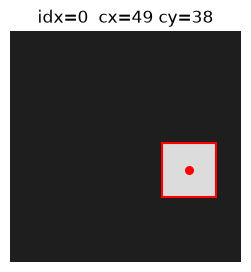

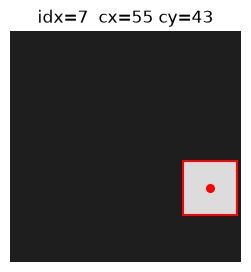

In [197]:
def show_square(ds, idx=0, side=15):
    img, target = ds[idx]
    cx, cy = target.tolist()
    plt.figure(figsize=(3, 3))
    plt.imshow(img.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    half = side / 2
    rect = patches.Rectangle(
        (cx - half, cy - half), side, side, fill=False, edgecolor="red", linewidth=1.5
    )
    plt.gca().add_patch(rect)
    plt.scatter([cx], [cy], c="red", s=30)
    plt.title(f"idx={idx}  cx={cx:.0f} cy={cy:.0f}")
    plt.axis("off")
    plt.show()


show_square(squares_ds, 0)
show_square(squares_ds, 7)


In [198]:
# 2.3 random_split + три DataLoader (как у автора).
# Пропорции на 200: train 140 / val 30 / test 30, batch_size=16.
# Ожидаемый вывод:
#   sizes: 140 30 30
#   batch X/y: torch.Size([16, 1, 64, 64]) torch.Size([16, 2])

gen = torch.Generator().manual_seed(0)
sq_train, sq_val, sq_test = random_split(squares_ds, [140, 30, 30], generator=gen)

sq_train_loader = DataLoader(sq_train, batch_size=16, shuffle=True)
sq_val_loader = DataLoader(sq_val, batch_size=16, shuffle=False)
sq_test_loader = DataLoader(sq_test, batch_size=16, shuffle=False)

sxb, syb = next(iter(sq_train_loader))
print("sizes:", len(sq_train), len(sq_val), len(sq_test))
print("batch X/y:", sxb.shape, syb.shape)
print("last train batch len:", len(sq_train) % 16)  # 140 % 16 = 12 → короткий хвост


sizes: 140 30 30
batch X/y: torch.Size([16, 1, 64, 64]) torch.Size([16, 2])
last train batch len: 12


In [199]:
need(
    (len(sq_train), len(sq_val), len(sq_test)) == (140, 30, 30),
    f"sizes={(len(sq_train), len(sq_val), len(sq_test))}",
)
need_tensor(sxb, "sxb")
need_tensor(syb, "syb")
need(tuple(sxb.shape) == (16, 1, 64, 64), f"sxb.shape={tuple(sxb.shape)}")
need(tuple(syb.shape) == (16, 2), f"syb.shape={tuple(syb.shape)}")
need(isinstance(sq_train_loader.sampler, torch.utils.data.RandomSampler), "train shuffle")
need(isinstance(sq_val_loader.sampler, torch.utils.data.SequentialSampler), "val no shuffle")
need(isinstance(sq_test_loader.sampler, torch.utils.data.SequentialSampler), "test no shuffle")
n_full = 0
last = None
for batch in sq_train_loader:
    n_full += 1
    last = batch[0].shape[0]
need(n_full == 9 and last == 12, f"ждали 8 полных + хвост 12, получили n={n_full} last={last}")
print("2.3 — верно")


2.3 — верно


## 3. Что унести из видео 6

| инструмент | когда |
|:---|:---|
| свой <span style="color:#7CDBA0">Dataset</span> | любой формат: json, CSV, клики, координаты |
| <span style="color:#E6C07B">ImageFolder</span> | только «папка = класс» для картинок |

`ImageFolder` не заменяет понимание `__getitem__` — он сам внутри делает то же самое.

Для регрессии ответ — **числа** `(B, K)`, не номер класса. Здесь `K=2` (`cx, cy`), как у автора.

### Чеклист

1. `ImageFolder(root, transform=...)` → `.classes`, `.class_to_idx`, `(картинка, int)`.
2. Без тензорного `transform` — PIL; для серого батча — `Grayscale(1) + ToTensor` (у нас `GRAY_TENSOR`).
3. Регрессия: json-словарь имя→числа; в `__getitem__` читаем один файл.
4. `random_split` + три `DataLoader`: train shuffle, val/test без; последний батч может быть короче.

**Дальше:** раздел «Видео 6» в `project/fashion_mnist.ipynb` (Fashion через `ImageFolder` + квадраты в проекте). Потом видео 7 — transforms.
